### Step 1: Import Libraries and Load the Dataset
- Import **pandas** for working with data tables.
- Import **numpy** for numerical calculations.
- Import `load_diabetes` from **sklearn.datasets** to get the sample diabetes dataset.
- Load the raw dataset into a variable named `diabetes`.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes

# Load the diabetes dataset
diabetes = load_diabetes()

diabetes

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
          0.01990749, -0.01764613],
        [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
         -0.06833155, -0.09220405],
        [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
          0.00286131, -0.02593034],
        ...,
        [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
         -0.04688253,  0.01549073],
        [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
          0.04452873, -0.02593034],
        [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
         -0.00422151,  0.00306441]]),
 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
         69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
         68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
         87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
        259.,  53., 190., 142.,  75., 142., 155., 225.,  59

### Step 2: Convert Raw Data into a Pandas DataFrame
- The raw dataset is stored in a dictionary-like format that is hard to read.
- We use `pd.DataFrame()` to turn the numbers (`diabetes.data`) and column headers (`diabetes.feature_names`) into a clean table called `my_df`.
- View the first 5 rows using `.head()`.

In [ ]:
# Create DataFrame with features
my_df = pd.DataFrame(data=diabetes.data, columns=diabetes.feature_names)

my_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


### Step 3: Add the Target Column to the Table
- In machine learning, the **target** is the final value we want our model to predict.
- Here, `diabetes.target` represents the progression level of diabetes after one year.
- We add it as a new column named `'target'` inside our table `my_df` and display the first 5 rows.

In [ ]:
# Add the target column
my_df['target'] = diabetes.target

my_df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Step 4: Separate the Input Features (X)
- We use uppercase `X` to store the input features (independent variables like age, BMI, blood pressure).
- We drop the `'target'` column so the model only sees the input features.
- Check the first 3 rows using `X.head(3)`.

In [ ]:
# Features (X) - Drop the target column from the DataFrame
X = my_df.drop(columns=['target'])
X.head(3)

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930


### Step 5: Separate the Target Output (y)
- We use lowercase `y` to store the target answers (dependent variable).
- We select only the `'target'` column from `my_df`.
- Check the first 3 answers using `y.head(3)`.

In [ ]:
# Target (y) - Select the target column from the DataFrame
y = my_df['target']
y.head(3)

0    151.0
1     75.0
2    141.0
Name: target, dtype: float64

### Step 6: Verify the Dimensions (Shapes) of X and y
- Check the row and column counts using `.shape`.
- `X.shape` should show (442, 10): 442 patients and 10 feature columns.
- `y.shape` should show (442,): 442 target labels (one for each patient).

In [ ]:
# Shape of features and target
print("Shape of features (X):", X.shape)
print("Shape of target (y):", y.shape)

Shape of features (X): (442, 10)
Shape of target (y): (442,)


### Step 7: Split Data into Training (80%) and Testing (20%) Sets
- Import `train_test_split` from `sklearn.model_selection`.
- Set `test_size=0.2` to save 20% of the data for testing, leaving 80% for training the model.
- Set `random_state=42` so the data is split in the exact same random way every time you run the code.

In [ ]:
from sklearn.model_selection import train_test_split

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


### Step 8: Confirm the Split Counts
- Print the sizes of `X_train`, `y_train`, `X_test`, and `y_test`.
- Training set has 353 rows (80%).
- Testing set has 89 rows (20%).

In [ ]:
print("Training set shape:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set shape:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training set shape:
X_train: (353, 10)
y_train: (353,)

Testing set shape:
X_test: (89, 10)
y_test: (89,)


### Step 9: Create and Train the Linear Regression Model
- Import `LinearRegression` from `sklearn.linear_model`.
- Create a model instance named `lr`.
- Call `.fit(X_train, y_train)` so the model learns the best-fit line connecting the input features to the target answers.

In [ ]:
from sklearn.linear_model import LinearRegression

# 1. Create a Linear Regression model instance
lr = LinearRegression()

# 2. Train the model on the training data
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


### Step 10: Make Predictions on Unseen Test Data
- Use `lr.predict(X_test)` to predict the diabetes progression values for the 89 test patients.
- Store the predictions in `y_pred`.
- Print `y_pred.shape` to confirm that it generated all 89 predictions.

In [ ]:
# Predict target values using test features
y_pred = lr.predict(X_test)

# Check shape of predictions
print(y_pred.shape)

(89,)


### Step 11: Calculate Evaluation Metrics & Intercept
- Import `r2_score`, `mean_squared_error`, and `mean_absolute_error` from `sklearn.metrics`.
- **R2 Score:** Measures how well the model fits the data (between 0 and 1, higher is better).
- **MSE (Mean Squared Error):** Average of the squared errors (penalizes large mistakes).
- **MAE (Mean Absolute Error):** Average difference in real units between actual values and predictions.
- **Intercept (`lr.intercept_`):** The baseline starting prediction if all feature values were zero.

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Calculate metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
intercept = lr.intercept_

print(r2)
print(mse)
print(mae)
print(intercept)

print("-" * 40)

# With f-strings for better formatting
print(f"R2 Score:            {r2:.2f}")
print(f"Mean Squared Error:  {mse:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")
print(f"Intercept:           {intercept:.2f}")

0.4526027629719197
2900.19362849348
42.79409467959994
151.34560453985995
----------------------------------------
R2 Score:            0.45
Mean Squared Error:  2900.19
Mean Absolute Error: 42.79
Intercept:           151.35


### Step 12: Build a Side-by-Side Comparison Table
- Create a new DataFrame called `plot_df` that places the real answers (`y_test`) right next to the model's guesses (`y_pred`).
- Display the top 10 rows using `.head(10)` to visually inspect individual predictions.

In [ ]:
# Convert test and predicted arrays into a DataFrame
plot_df = pd.DataFrame({
    'Actual Values': y_test,
    'Predicted Values': y_pred
})

plot_df.head(10)

,Actual Values,Predicted Values
287,219.0,139.547558
211,70.0,179.517208
72,202.0,134.038756
321,230.0,291.417029
73,111.0,123.789659
418,84.0,92.172347
367,242.0,258.232389
354,272.0,181.337321
281,94.0,90.224113
148,96.0,108.633759


### Step 13: Plot Actual vs. Predicted Values as a Scatter Plot
- Use Pandas `.plot(kind='scatter')` to plot the real values on the X-axis and predicted values on the Y-axis.
- Set `alpha=0.5` to make overlapping dots semi-transparent and easy to see.
- Enable grid lines with `grid=True`.

<Axes: title={'center': 'Predicted vs Actual Values in Linear Regression'}, xlabel='Actual Values', ylabel='Predicted Values'>

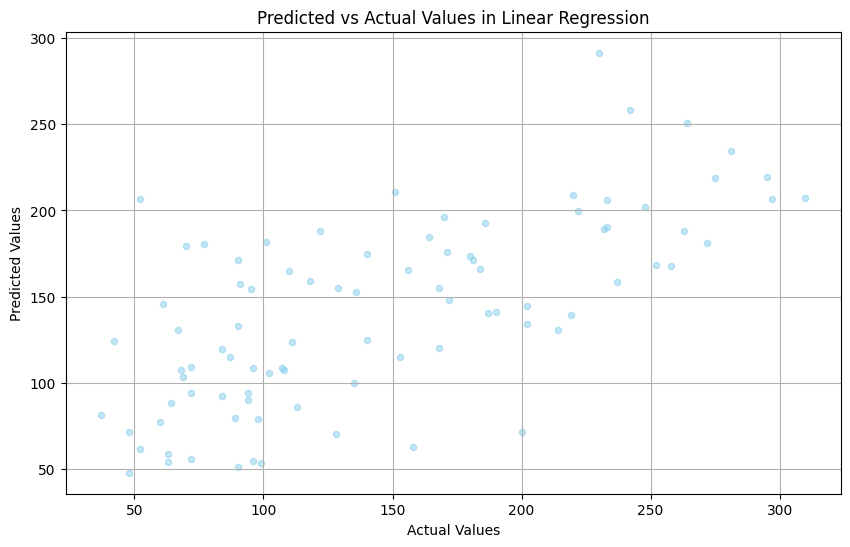

In [ ]:
# Create deeply customized scatter visualization using Pandas .plot()
ax = plot_df.plot(
    kind='scatter',
    x='Actual Values',
    y='Predicted Values',
    title='Predicted vs Actual Values in Linear Regression',
    figsize=(10, 6),
    color='skyblue',
    alpha=0.5,
    grid=True
)

ax

### Step 14: Draw the Diagonal Best-Fit Reference Line
- Draw a red line across the plot from `y.min()` to `y.max()`.
- This red line represents 100% perfect predictions (where Actual = Predicted).
- Dots grouped closely around this line confirm that the model's predictions align well with reality.

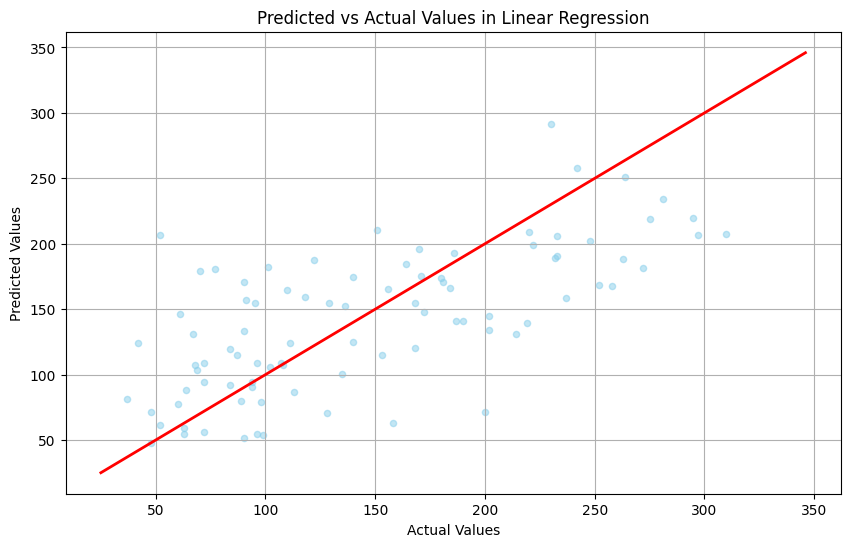

In [ ]:
# Create deeply customized scatter visualization using Pandas .plot()
ax = plot_df.plot(
    kind='scatter',
    x='Actual Values',
    y='Predicted Values',
    title='Predicted vs Actual Values in Linear Regression',
    figsize=(10, 6),
    color='skyblue',
    alpha=0.5,
    grid=True
)

# Draw the red diagonal reference line across the plot
ax.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linewidth=2)

### Step 15: Create the Residual Plot to Check for Prediction Errors
- **Residual** means error: `Residual = Actual Value - Predicted Value` (`y_test - y_pred`).
- Store the predictions and residuals in a new DataFrame called `residual_df`.
- Plot predicted values on the X-axis and residuals on the Y-axis.
- Draw a horizontal dashed red line at `y = 0` using `ax.axhline()` to mark the zero-error line.
- **Evaluation rule:** If the dots are scattered randomly above and below zero without forming a curve or funnel shape, your linear regression model is a solid fit!

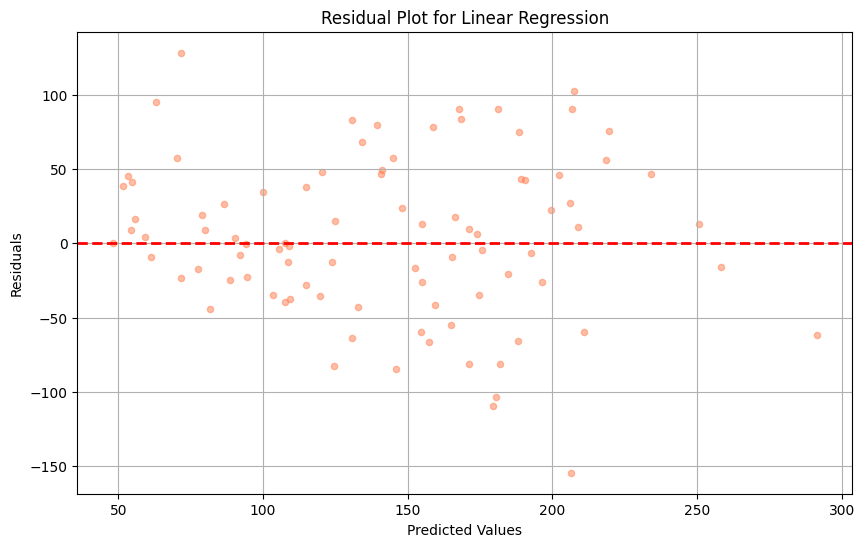

In [ ]:
# Put predicted values and residuals into a DataFrame
residual_df = pd.DataFrame({
    'Predicted Values': y_pred,
    'Residuals': y_test - y_pred
})

# Create deeply customized residual visualization using Pandas .plot()
ax = residual_df.plot(
    kind='scatter',
    x='Predicted Values',
    y='Residuals',
    title='Residual Plot for Linear Regression',
    figsize=(10, 6),
    color='coral',
    alpha=0.5,
    grid=True
)

# Draw the red horizontal reference line at zero error
ax.axhline(y=0, color='red', linestyle='--', linewidth=2)